## Logistic Regression

In [3]:
#load libraries
# Load Libraries
import warnings
warnings.filterwarnings("ignore")
import joblib
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from evaluation_script import evaluate_model

a


In [15]:
# Load Processed Data
data = joblib.load('../building/dataset_bundle.pkl')

X_train = data['X_train']
y_train = data['y_train']
X_test = data['X_test']
y_test = data['y_test']


done


### Finding the best parameters

In [17]:
param_grid = {
    'C': [0.1, 0.5, 1, 10, 50, 100], 
    'max_iter': [250], 
    'fit_intercept': [True],
    'intercept_scaling': [1],
    'penalty': ['l2'], 
    'tol': [0.00001, 0.0001, 0.000001]
}

In [20]:
# Create Search Space
log_primal_Grid = GridSearchCV(LogisticRegression(solver='lbfgs', class_weight='balanced'),
param_grid,                                
cv = 10,                                
refit = True,  
scoring = 'f1',                              
verbose = 1)
print("done")

done


In [21]:
log_primal_Grid.fit(X_train , y_train)
best_model = log_primal_Grid.best_estimator_
best_model


Fitting 10 folds for each of 18 candidates, totalling 180 fits
done


In [22]:
best_model

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",1e-05
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",250
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in th

In [23]:
evaluate_model(best_model, X_test, y_test)

{'Recall_Churn': 0.6524064171122995,
 'Precision_Churn': 0.3283983849259758,
 'F1_Churn': 0.4368845120859445,
 'ROC_AUC': 0.7430787142096019}

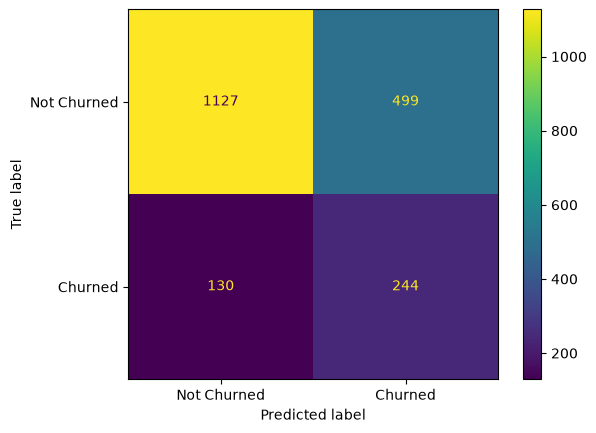

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

y_pred = log_primal_Grid.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Churned", "Churned"]
)

plt.show()

### Evaluation Focus: Recall

For this churn prediction problem, **recall is more important than precision**.

Our main objective is to identify as many customers who are actually going to churn as possible. A **false negative** means the model predicts that a customer will not churn when they actually do churn. Missing these customers can result in lost opportunities to take preventive retention actions.

Recall directly measures how effectively the model identifies actual churners.

* Therefore, we prioritize **recall over precision**, accepting that a higher recall may result in some additional false positives. The goal is to minimize the number of actual churners that the model fails to identify.

